<a href="https://colab.research.google.com/github/nbulotti/2026_ML_EES/blob/main/live/part-II/3.5-wildfire-susceptibility-mapping-exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> Notebook-friendly copy of `part-II/3.5-wildfire-susceptibility-mapping-exercises.ipynb`, generated by `tools/make_live.py`. Edit the book notebook, not this file.

In [ ]:
# --- environment setup (generated, not part of the lesson) ---
# Colab and Kaggle do not ship every package this notebook imports.
# This is a no-op in an environment that is already set up.
import importlib.util
import subprocess
import sys

for module, package in {"geopandas": "geopandas", "pooch": "pooch"}.items():
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

# 3.5) (Exercises) Wildfire Susceptibility Mapping

---



**Credits**

This online tutorial would not be possible without invaluable contributions from [Andrea Trucchia](https://www.researchgate.net/profile/Andrea-Trucchia) (reduced data, methods), [Giorgio Meschi](https://www.linkedin.com/in/giorgio-meschi-86216b180/) (code, methods), and [Marj Tonini](https://www.researchgate.net/profile/Marj-Tonini-2) (presentation, methods). The methodology builds upon the following article:

[Trucchia, A.; Meschi, G.; Fiorucci, P.; Gollini, A.; Negro, D., Defining Wildfire Susceptibility Maps in Italy for Understanding Seasonal Wildfire Regimes at the National Level, *Fire*, (2022)](https://www.mdpi.com/2571-6255/5/1/30)

which generalizes the study below from the Liguria region (our case study) to all of Italy:

[Tonini, Marj, et al. "A machine learning-based approach for wildfire susceptibility mapping. The case study of the Liguria region in Italy." *Geosciences* 10.3 (2020): 105.](https://www.mdpi.com/2076-3263/10/3/105)



---

In week 3's final notebook, we will train classifiers on real [wildfire](https://en.wikipedia.org/wiki/Wildfire) data to map the fire risk in different regions of Italy. To keep the data size manageable, we will focus on the coastal [Liguria region](https://en.wikipedia.org/wiki/Liguria) that experiences a lot of wildfires, especially during the winter.

**🎯 Learning objectives**

- Use classification methods for environmental risk analysis
- Train classifiers on real data to map wildfire susceptibility in Liguria, Italy
- Benchmark the classifiers with scikit-learn's confusion matrix
- Run a sensitivity analysis to see how predictions change with season and input selection

## Machine Learning for Environmental Risk Analysis

For environmental sciences practioners, one of the scenarios where machine learning can be particularly useful is risk analysis. Environmental risk analysis involves predicting where potential hazards may occur; it also involves understanding why some regions are more vulnerable to hazards than others. Machine learning models can be useful for these tasks because they can analyze large datasets containing different environmental predictors (e.g., weather conditions, soil conditions etc.) in an effective manner. By learning the hidden links between predictors and hazard risks, we may also gain new insights on what predictors or patterns are useful for creating early hazard warning systems.

In this exercise, we ask you to use the machine learning classifiers we learned in this chapter to recreate wildfire susceptibility maps for the Liguria region of Italy. The basic idea is to use ML classifiers to analyze a dataset with observations in weather conditions, vegetation cover, and topography information. The goal will be to understand how different factors enhance or reduce the probability of firefire in Liguria, which can help authorities and decision-makers to apply resources to critical areas for hazard prevention.

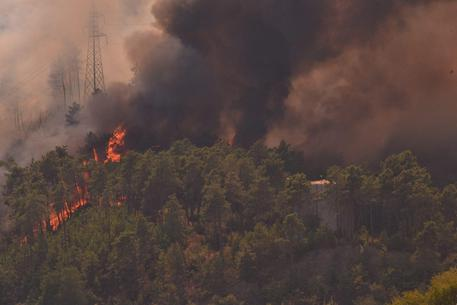

**Caption**: A wildfire in Italy. Can we predict which locations are most susceptible to wildfires using simple classifiers? 🔥

**Source**: [ANSA](https://www.ansa.it/english/news/2015/08/14/wildfires-in-italy-up-120-this-summer-on-past-two-years_f6e4eff7-ac07-4f9e-aa5a-e61f8c2ad7f2.html)

Let's start by downloading and loading the datasets into memory using the [`pooch`](https://pypi.org/project/pooch/) and [`GeoPandas`](https://geopandas.org/en/stable/) libraries:

In [1]:
# Install geopandas
%pip install geopandas

In [24]:
import geopandas as gpd
import numpy as np
import pickle
import pooch
import sys, types
import pandas as pd

In [26]:
numeric_module = types.ModuleType('pandas.core.indexes.numeric')
numeric_module.Int64Index = pd.Index
numeric_module.UInt64Index = pd.Index
numeric_module.Float64Index = pd.Index
numeric_module.NumericIndex = pd.Index
# register it --> when pickle looks for 'pandas.core.indexes.numeric' it finds our fake one
sys.modules['pandas.core.indexes.numeric'] = numeric_module

In [27]:
# Function to load the data
# Function to load the data
def load_data(path):

    # Load the content of the pickle file
    with open(path, "rb") as fh:
        points_df = pickle.load(fh)

    # rebuild a clean, modern DataFrame column by column --> drops the old geometry objects
    # (they were saved with an old shapely version) --> we recreate the geometry right below
    points_df = pd.DataFrame({col: points_df[col].values for col in points_df.columns if col != 'geometry'},
                             index=points_df.index)

    # Convert it to a Geopandas `GeoDataFrame` for spatial analysis
    points_df = gpd.GeoDataFrame(points_df,
                                 geometry=gpd.points_from_xy(np.float64(points_df.x),
                                                             np.float64(points_df.y)))
    return points_df

In [28]:
# Fetch and cache verified snapshots of the Liguria wildfire dataset
WILDFIRE_FILES = {
    "points_liguria_vs0.1.pkl": "sha256:e8ebc70f972b5af4ef3d6110dcd61ce01ce5a830dcdb7d2c9e737aeab781606c",
    "fires_liguria_vs0.1.pkl": "sha256:361f067aafbac8add8f8a9a5c630df3c962cd37a2f125f420e7b9330fd0a1a4c",
}

In [29]:
def fetch_wildfire_file(filename):
    return pooch.retrieve(
        url=f"https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-II/{filename}",
        known_hash=WILDFIRE_FILES[filename],
        fname=filename,
        path=pooch.os_cache("mlees"),
    )

In [30]:
variables_path = fetch_wildfire_file("points_liguria_vs0.1.pkl")
wildfires_path = fetch_wildfire_file("fires_liguria_vs0.1.pkl")

In [31]:
# Load the data and convert it to a GeoPandas `GeoDataFrame`
# This can take a minute
variables = load_data(variables_path)
wildfires = load_data(wildfires_path)

/tmp/ipykernel_2110/1446854595.py:7: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  points_df = pickle.load(fh)
/tmp/ipykernel_2110/1446854595.py:7: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case,

(previous_ex)=

### Part I: Pre-Processing the Dataset for Classification

**Q1) After analyzing the topography and land cover data provided in `variables`, create your input dataset `inputs` from `variables` to predict the occurence of wildfires (`wildfires`). Keep at least one categorical variable (`veg`, `bioclim`, or `phytoclim`).**

Hint 1: Refer to the documentation [at this link](https://github.com/mirkodandrea/liguria-fire-susceptibility/blob/master/variables%20explaination.md) to know what the different `keys` of `variables` refer to.

Hint 2: You may refer to Table 1 of [Tonini et al.](https://www.mdpi.com/2076-3263/10/3/105), copied below, to choose your input variables, although we recommend starting with less inputs at first to build a simpler model and avoid overfitting.

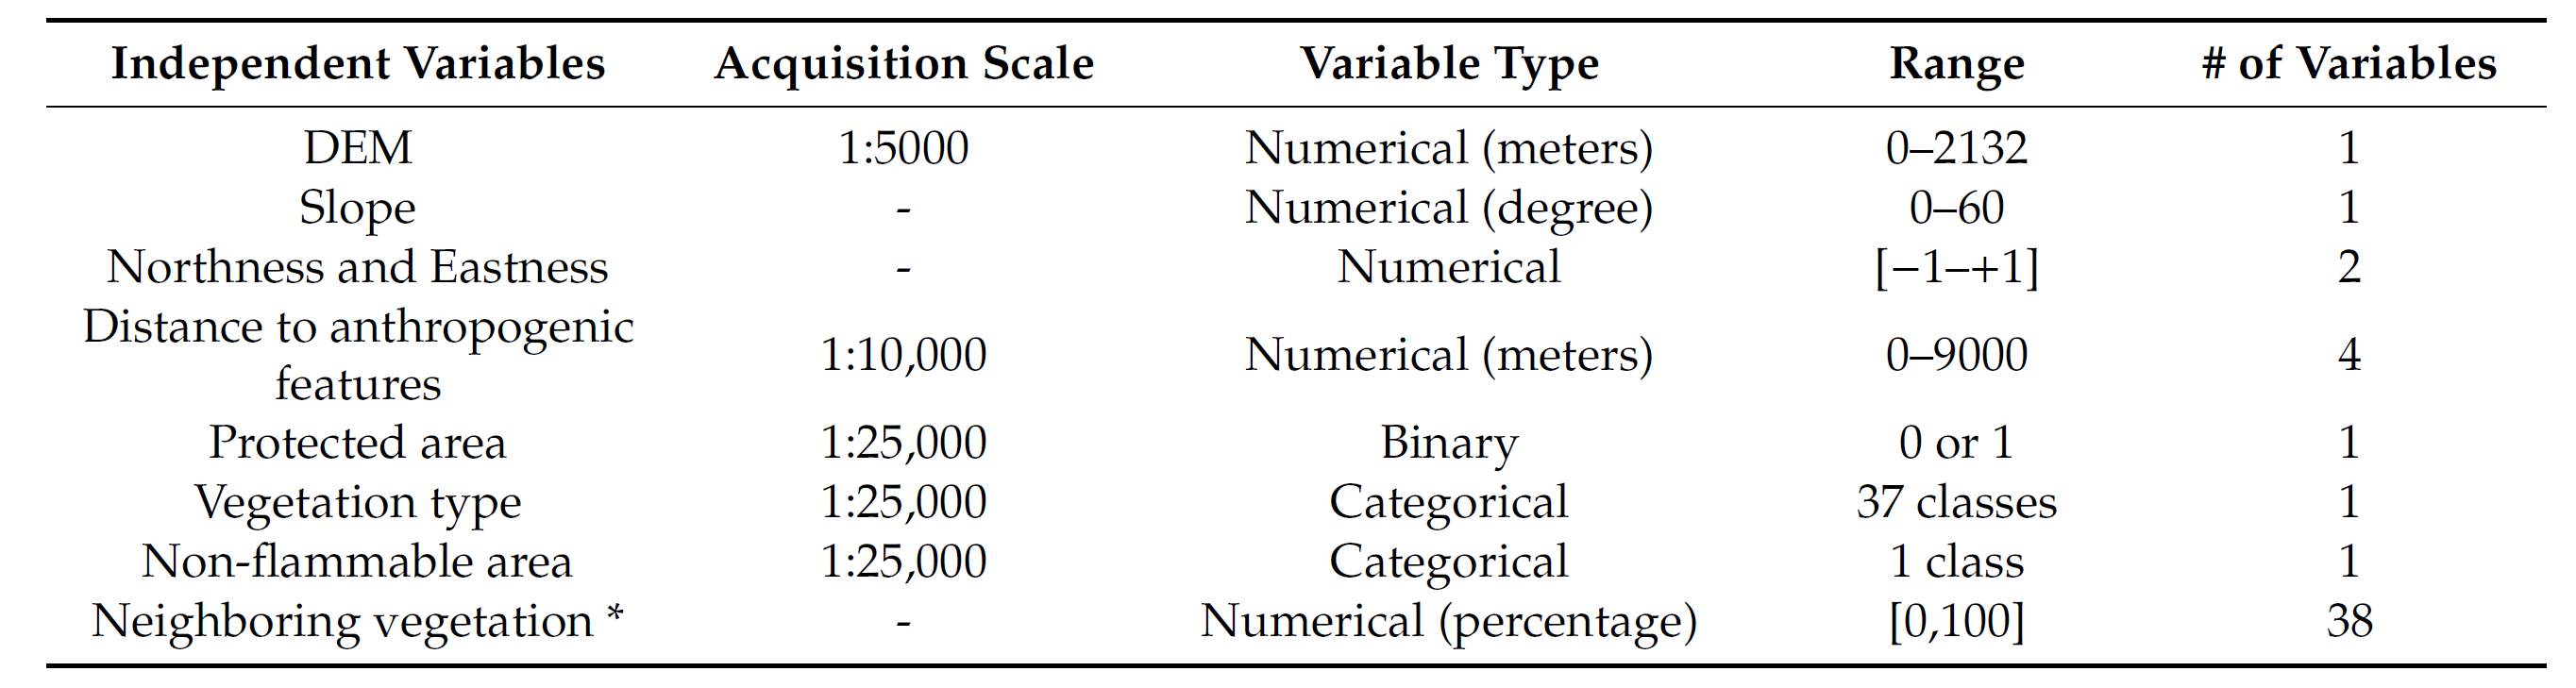

Here are some pandas commands you could use to explore your data.
[.head()](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.head.html)
[.columns()](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.columns.html)
[.describe()](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html)

In [32]:
# Explore the `variables` dataset
#########################################################################################################
# 1. What kind of data is provided in the "variables" panda DataFrame?
#########################################################################################################
# Can you print the variable names?
print(variables.columns)

Index(['row', 'col', 'x', 'y', 'dem', 'slope', 'north', 'east', 'veg',
       'urban_d', 'roads_d', 'crops_d', 'tracks_d', 'bioclim', 'phytoclim',
       'temp_1', 'temp_2', 'prec_1', 'prec_2', 'perc_0', 'perc_21', 'perc_22',
       'perc_23', 'perc_32', 'perc_33', 'perc_34', 'perc_37', 'point_index',
       'geometry'],
      dtype='object')


In [33]:
# Can you print a table with all the statistics of each variable in the dataframe?
print(variables.describe())

                 row            col             x             y  \
count  528669.000000  528669.000000  5.286690e+05  5.286690e+05   
mean      456.389826     962.931258  1.475397e+06  4.901395e+06   
std       240.887463     555.848154  5.558482e+04  2.408875e+04   
min         1.000000       1.000000  1.379204e+06  4.848434e+06   
25%       256.000000     491.000000  1.428204e+06  4.882034e+06   
50%       411.000000     894.000000  1.468504e+06  4.905934e+06   
75%       650.000000    1463.000000  1.525404e+06  4.921434e+06   
max       986.000000    2065.000000  1.585604e+06  4.946934e+06   

                 dem          slope          north           east  \
count  528669.000000  528669.000000  528669.000000  528669.000000   
mean      538.422731      18.021345      -0.097896       0.017473   
std       336.707659       8.175467       0.701131       0.705994   
min         0.000000       0.000000      -1.000000      -1.000000   
25%       281.000000      12.281326      -0.787887 

There are 25 columns (variables) in the DataFrame. It is probably best to start simple and just use a few variables to make the wildfire prediction.

Can we use a very simple model to predict wildfires ❓

A simple model might contain `dem`, `slope`, `veg` and `bioclim`. We can use it as a baseline to evaluate model performance when you use other combinations to train the model.

However, we cannot tell you which combination would perform the best as we have not done an extensive search while preparing the notebook.

In [34]:
# Here you will filter the DataFrame so that only the variables you want are in the input
############################################################################################################
# 1. Drop down the names of variables you want here so that pandas can do the filtering for you.
############################################################################################################
vars_tokeep = ['dem', 'slope', 'veg', 'bioclim']

In [35]:
############################################################################################################
# 2. Create a new dataframe 'inputs' with just the variables you want
############################################################################################################
inputs = variables[vars_tokeep] # Filter 'variables' dataframe --> list of columns --> keeps only those 4
inputs.head() # print the first few columns to make sure everything works fine (head is a method --> ())

,dem,slope,veg,bioclim
point_index,,,,
0,563,20.843185,34,15
1,527,23.599121,34,15
2,525,26.699856,34,15
3,519,24.512413,34,15
4,532,20.421495,34,15


**Q2) To avoid making inaccurate assumptions about which types of vegetation and non-flammable area are most similar, convert your categorical inputs into one-hot vectors.**

Hint 1: You may use the [`fit_transform`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html#sklearn.preprocessing.OneHotEncoder.fit_transform) method of `scikit-learn`'s [`OneHotEncoder`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html) class to convert categorical inputs into one-hot vectors.

Hint 2: Don't forget to remove the categorical variables from your input dataset, e.g. using [`drop`](https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoDataFrame.html) if you are still using a `GeoDataFrame`, or [`del`](https://docs.python.org/3/reference/simple_stmts.html#the-del-statement)/[`pop`](https://docs.python.org/3/library/stdtypes.html#dict.pop) if you are working with a Python dictionary.

Hint 3: There are numerous ways to change the categorical data into one-hot vectors. It is quite easy to do in `pandas`, but scikit-learn also provides some transformers that could be useful, including [.ColumnTransformer()](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html) and [Pipeline()](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html).

In the guided reading, you have seen how these functions are used. Try experiment with them and see if you prefer using these scikit transformers or pandas.

In [36]:
############################################################################################################
# 1. Import OneHotEncoder for 'veg' and 'bioclim' data, and pandas
############################################################################################################
from sklearn.preprocessing import OneHotEncoder
import pandas as pd
############################################################################################################
# 2. Initiate OneHotEncoder object, set the 'sparse_output' option to False
############################################################################################################
# sparse_output=False --> normal numpy array instead of a sparse matrix --> easy to turn into a DataFrame
enc = OneHotEncoder(sparse_output=False)

In [37]:
############################################################################################################
# 3. Convert categorical variables into one-hot vectors
############################################################################################################
# Convert categorical variables with 'enc'
# one-hot --> each category gets its own 0/1 column --> the model can't assume "veg 34 > veg 21"
# double brackets --> DataFrame with 1 column (the encoder wants 2D input)
veg_onehot = enc.fit_transform(variables[['veg']])
bioclim_onehot = enc.fit_transform(variables[['bioclim']])
# Convert 'veg_onehot' and 'bioclim_onehot' to pandas DataFrames
veg_transform = pd.DataFrame(veg_onehot) # veg
bio_transform = pd.DataFrame(bioclim_onehot) # bioclim

In [38]:
############################################################################################################
# 4. Print the shape of 'veg_transform'
############################################################################################################
# (number of points, number of vegetation categories)
print(veg_transform.shape)
# Don't change these!
veg_transform= veg_transform.add_prefix('v_')
bio_transform= bio_transform.add_prefix('b_')

(528669, 7)


In [39]:
############################################################################################################
# 5. Convert 'inputs' into Panda DataFrame
############################################################################################################
# reset_index(drop=True) --> IMPORTANT: 'variables' is indexed by point_index, which has duplicates
# --> without it, join() would match rows by label and glue the one-hot vectors to the WRONG points
# after the reset --> index 0, 1, 2... exactly like veg_transform and bio_transform
inputs_gdf = pd.DataFrame(inputs).reset_index(drop=True)
############################################################################################################
# 6. Add 'veg_transform' and 'bio_transform' into the inputs DataFrame
############################################################################################################
# join --> adds the new columns side by side (rows matched by index --> now 0..N-1 for everyone)
inputs_gdf = inputs_gdf.join(veg_transform)
inputs_gdf = inputs_gdf.join(bio_transform)

In [40]:
############################################################################################################
# 7. Use .drop() to delete 'veg' and 'bioclim' from DataFrame
############################################################################################################
# the original categorical columns are now redundant --> replaced by their one-hot columns
# drop() returns a NEW DataFrame --> we must assign it back, otherwise nothing changes!
inputs_gdf = inputs_gdf.drop(columns=['veg','bioclim'])
inputs_gdf.head()

,dem,slope,v_0,v_1,v_2,v_3,v_4,v_5,v_6,b_0,b_1,b_2,b_3,b_4
0,563,20.843185,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
1,527,23.599121,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
2,525,26.699856,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
3,519,24.512413,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
4,532,20.421495,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0


Now that we built our `inputs` dataset, we are ready to build our `outputs` dataset!

**Q3) Using the `point_index` column of `wildfires` and `variables`, create your `outputs` dataset, containing 1 when there was a wildfire and 0 otherwise.**

Hint: Check that `inputs` and `outputs` have the same number of cases by looking at their `.shape[0]` attribute.

In [41]:
#####################################################################################################################
# 1. Use numpy to initialize an outputs array with the same shape as the 'point_index' column in the variables table
#####################################################################################################################
# one 0 per point of the map --> by default "no wildfire"
outputs = np.zeros_like(variables['point_index'])
#####################################################################################################################
# 2. Pull out the indices of wildfire locations from the pandas DataFrame 'wildfires'
#####################################################################################################################
# the index of 'wildfires' = the point_index of every burned point
wildfiresindex = wildfires.index

In [42]:
#####################################################################################################################
# 3. Fill the zero array with ones if a fire broke out at a specific location index.
# Here you can use a for loop for this task
#####################################################################################################################
# set --> checking "is x in the set?" is instant, even with 80k fires
fire_set = set(wildfiresindex)
# enumerate --> pos = row POSITION (0, 1, 2...), pidx = the point_index LABEL of that row
# careful: positions and labels stop matching after the first duplicated point --> we need both
for pos, pidx in enumerate(variables.index):
  if pidx in fire_set:
    outputs[pos] = 1

# clean integer labels 0/1 instead of floats
outputs = outputs.astype(int)

In [43]:
#####################################################################################################################
# 4. Check that `inputs` and `outputs` have the same shape[0]
#####################################################################################################################
# same number of points --> one label for every row of inputs
print(inputs_gdf.shape[0], outputs.shape[0])
assert inputs_gdf.shape[0] == outputs.shape[0]
# share of burned points --> ~15% --> classes are imbalanced (keep this in mind for the accuracy!)
print(f'Fraction of points with a wildfire: {outputs.mean():.1%}')

528669 528669
Fraction of points with a wildfire: 15.5%


**Q4) Separate your `inputs` and `outputs` datasets into a training and a test set. Keep at least 20% of the dataset for testing.**

Hint 1: You may use `scikit-learn`'s [`train_test_split`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) function.

Hint 2: If you are considering optimizing the hyperparameters of your classifier, form a validation dataset as well.

Hint 3: We recommend performing the split on the indices so that it is easier to track what points are in which dataset after splitting. You will have an easier time when plotting the susceptibility map.

In [44]:
#####################################################################################################################
# 1. Import train_test_split()
#####################################################################################################################
from sklearn.model_selection import train_test_split

In [45]:
#####################################################################################################################
# 2. Create a list with all indices in the input [0,1,2,...]
#####################################################################################################################
all_indices = list(range(len(inputs_gdf)))

In [46]:
#####################################################################################################################
# 3. Convert the inputs_gdf dataframe to numpy array
#####################################################################################################################
inputs_gdf = inputs_gdf.to_numpy()

In [47]:
#####################################################################################################################
# 4. Apply train_test_split on 'all_indices', and store training indices in 'indx_train', test indices in 'indx_test'
#####################################################################################################################
# we split the INDICES, not the data --> later we always know which point is where (handy for the map)
indx_train, indx_test = train_test_split(all_indices, test_size=0.2, random_state=42)

In [49]:
#####################################################################################################################
# 5. Create training and test sets with indx_train and indx_test
#####################################################################################################################
# fancy indexing --> numpy array[list of indices] --> picks those rows
X_train, X_test, y_train, y_test = inputs_gdf[indx_train], inputs_gdf[indx_test], outputs[indx_train], outputs[indx_test]


In [50]:
# Check the shape of your training(/validation)/test sets
# and make sure you kept at least 20% of your dataset for testing
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)
print(f'Test fraction: {X_test.shape[0] / inputs_gdf.shape[0]:.1%}')

(422935, 14) (105734, 14) (422935,) (105734,)
Test fraction: 20.0%


Congratulations, you have created a viable wildfire dataset to train a machine learning classifier! 😃 Now let's get started 🔥

### Part II: Training and Benchmarking the Machine Learning Classifiers

**Q5) Now comes the machine learning fun! 🤖 Train multiple classifiers on your newly-formed training set, and make sure that at least one has the `predict_proba` method once trained.**

Hint: You may train a [`RandomForestClassifier`](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html) or an [`ExtraTreesClassifier`](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.ExtraTreesClassifier.html), but we encourage you to be creative and include additional classifiers you find promising! 💻

In [51]:
#####################################################################################################################
# 1. Import RandomForestClassifier
#####################################################################################################################
from sklearn.ensemble import RandomForestClassifier
#####################################################################################################################
# 2. Convert X_train and X_test into pandas DataFrame
#####################################################################################################################
X_train = pd.DataFrame(X_train)
X_test = pd.DataFrame(X_test)

In [52]:
X_train

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,143.0,3.441056,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,204.0,21.165070,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,304.0,28.740286,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,318.0,18.950947,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,522.0,19.906359,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
422930,431.0,14.090720,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
422931,560.0,3.790979,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
422932,213.0,19.034899,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
422933,413.0,0.955438,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [54]:
#####################################################################################################################
# 3. Initiate RF classifier and fit it on training set
#####################################################################################################################
# 100 trees | n_jobs=-1 --> all CPU cores (~1 min on Colab with 420k points) | random_state --> reproducible
# RandomForest has predict_proba --> needed later for the susceptibility map
rfc = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)
rfc.fit(X_train, y_train)

RandomForestClassifier(n_jobs=-1, random_state=42)

In [ ]:
# (Optional) Conduct a hyperparameter search on the validation set
# e.g., using scikit-learn's RandomizedSearchCV

**Q6) Compare the performance and confusion matrices of your classifiers on the test set. Which classifier performs best in your case?**

Hint 1: You may use the [`accuracy_score`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html) to quantify your classifier's performance, but don't forget there are [many other performance metrics to benchmark binary classifiers](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics).

Hint 2: You can directly calculate the confusion matrix using `scikit-learn`'s [`confusion_matrix` function](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html).

In [55]:
#####################################################################################################################
# 1. Import accuracy_score, confusion_matrix, and ConfusionMatrixDisplay
#####################################################################################################################
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [56]:
#####################################################################################################################
# 2. Use rfc to make prediction on test set
#####################################################################################################################
rfc_preds = rfc.predict(X_test)

In [57]:
#####################################################################################################################
# 3. Use accuracy_score to infer trained classifier performance
#####################################################################################################################
rfc_acc = accuracy_score(y_test, rfc_preds)
print(f'RF test accuracy: {rfc_acc:.2%}')
# careful: ~85% of the points have NO fire --> a model always saying "no fire" would already get ~85%!
# --> the confusion matrix tells us much more

RF test accuracy: 85.28%


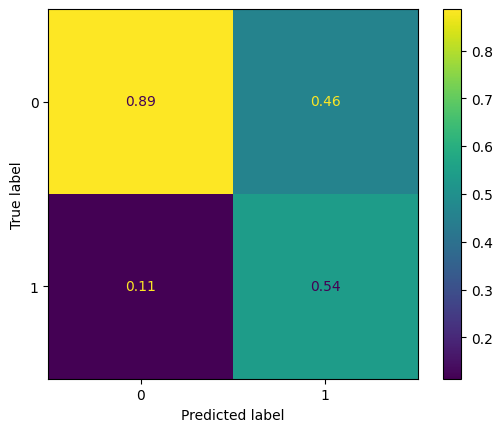

In [58]:
#####################################################################################################################
# 4. Plot the confusion matrix
#####################################################################################################################
# rows = true class, columns = predicted class
# normalize='pred' --> each COLUMN sums to 1 --> "when the model says fire, how often is it right?"
cm = confusion_matrix(y_test, rfc_preds, normalize='pred') # Get a confusion matrix 'cm', use 'pred' for the normalize option
disp = ConfusionMatrixDisplay(confusion_matrix = cm) # Use ConfusionMatrixDisplay to visualize 'cm'
disp.plot()

For comparison, below is the confusion matrix obtained by the paper's authors:


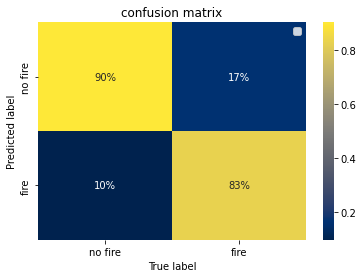

### Part III: Making the Susceptibility Map

**Q7) Using all the classifiers you trained that have a `predict_proba` method, predict the probability of a wildfire over the entire dataset.**

Hint: `predict_proba` will give you the probability of both the presence and absence of a wildfire, so you will have to select the right probability.

In [59]:
#####################################################################################################################
# 1. Predict the probability of a wildfire or not on the *entire* dataset
#####################################################################################################################
# whole map, not only the test set --> we want a value for EVERY point of Liguria
# pd.DataFrame --> same format the model was trained on (avoids the "feature names" warning)
predprob_rf = rfc.predict_proba(pd.DataFrame(inputs_gdf)) # Use .predict_proba in the 'rfc' classifier to process the entire dataset

In [60]:
#####################################################################################################################
# 2. Extract the probability of a wildfire happening over the entire period of the dataset for each instance
#####################################################################################################################
# predict_proba --> shape (N, 2): column 0 = P(no fire), column 1 = P(fire) --> we want column 1
rf_testprob_fire = predprob_rf[:, 1] # Hint: predprob_rf shape = [:,2], select the second column

**Q8) Make the susceptibility map 🔥**

Hint 1: The `x` and `y` coordinates for the map can be extracted from the `variables` dataset.

Hint 2: You can simply [`scatter`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html) `x` versus `y`, and color the dots according to their probabilities (`c`=probability of a wildfire) to get the susceptibility map.

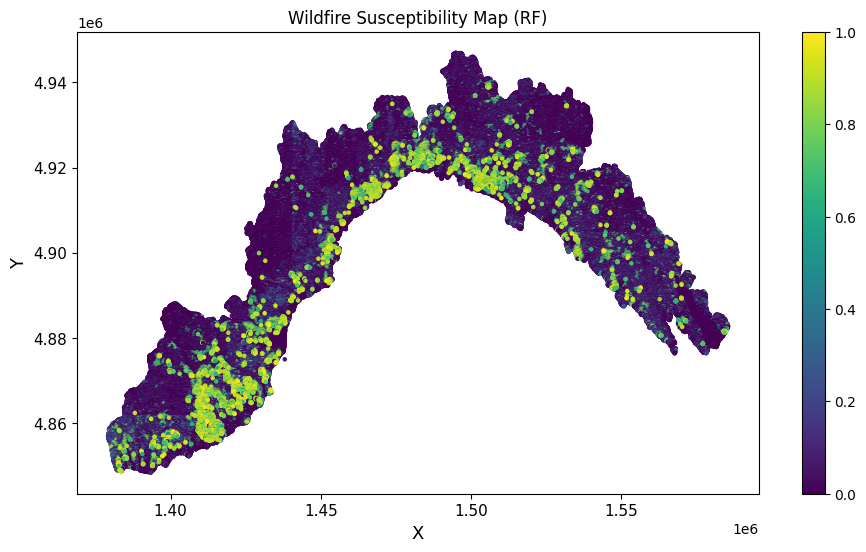

In [61]:
# Scatter ['x'] vs ['y'] columns in the entire dataframe and color the dots with the predicted probability 'rf_testprob_fire'
# to make the susceptibility map

import matplotlib.pyplot as plt
fig,ax = plt.subplots(1,figsize=(6+5,4+2))
# every point at its real coordinates --> color = predicted fire probability (yellow = high, purple = low)
cmploy = ax.scatter(variables['x'],variables['y'],s=5,c=rf_testprob_fire,cmap='viridis')
plt.colorbar(cmploy,ax=ax)
ax.set_title('Wildfire Susceptibility Map (RF)')
ax.set_ylabel('Y',size=13)
ax.set_xlabel('X',size=13)
ax.tick_params(axis='both', which='major', labelsize=11)
plt.show()

You should get a susceptibility map that looks like the one below. Does your susceptibility map depend on the classifier & the inputs you chose? Which map would you trust most?

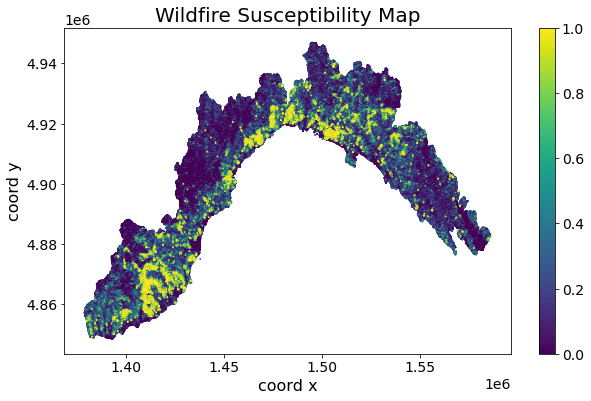

It seems like our model was too simple to generate a useful map 😞 .
Your TA actually experimented training a RandomForest model with 10 variables and got a 91% accuracy!

So you should definitely try combinations of different variables to get a map that is better than what you just got.

## Bonus Exercise 4: Exploring the Susceptibility Map's Sensitivity to Seasonality and Input Selection

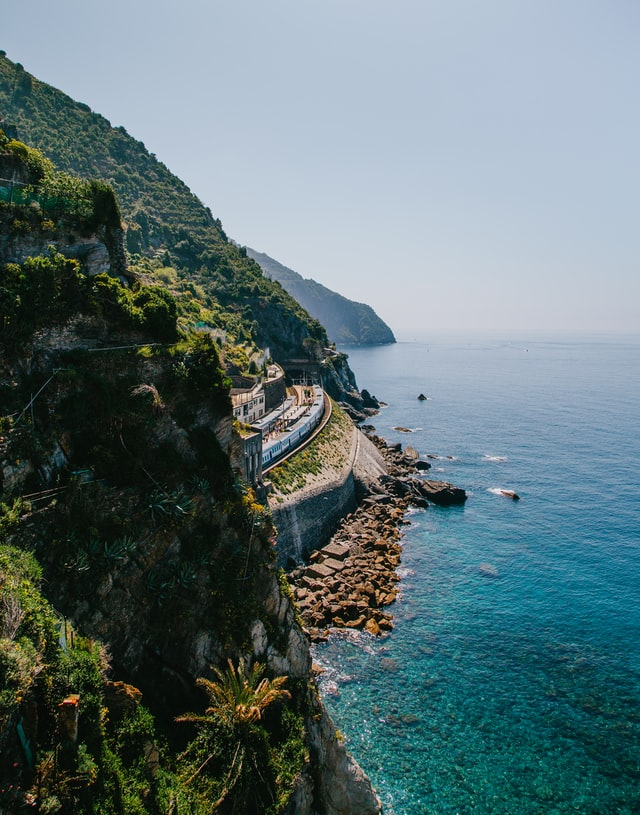

**Caption:** The Liguria region (Cinque Terre), after you save it from raging wildfires using machine learning ✌

### Part I: Seasonality

**Q1) Using the `season` column of `wildfires`, separate your data into two seasonal datasets (1=Winter, 2=Summer).**

Hint: When splitting your `inputs` into two seasonal datasets, keep in mind that `temp_1` and `prec_1` are the climatological mean temperatures and precipitation during winter, while `temp_2` and `prec_2` are the climatological mean temperature and precipitation during summer.  

In [62]:
# Identify indices for which the wildfires occured during winter/summer
# season column --> 1 = winter, 2 = summer
winter_idx = wildfires.index[wildfires['season'] == 1]
summer_idx = wildfires.index[wildfires['season'] == 2]

# labels per season --> isin() matches by point_index LABEL --> safe even with the duplicated points
outputs_winter = variables.index.isin(winter_idx).astype(int)
outputs_summer = variables.index.isin(summer_idx).astype(int)

In [63]:
# Use these indices to split your `inputs` and `outputs` datasets
# into two seasonal datasets
from sklearn.preprocessing import OneHotEncoder
import pandas as pd

# common predictors: topography + distances from human infrastructure
base_vars = ['dem', 'slope', 'north', 'east', 'urban_d', 'roads_d', 'crops_d', 'tracks_d']

def make_inputs(cols, categorical=('veg', 'bioclim')):
    """Numerical columns + one-hot encoded categorical columns --> one clean DataFrame"""
    # reset_index --> rows numbered 0..N-1, same order as variables and the outputs
    inp = pd.DataFrame(variables[cols]).reset_index(drop=True)
    for cat in categorical:
        enc = OneHotEncoder(sparse_output=False)
        # get_feature_names_out --> readable names like 'veg_34' instead of 0, 1, 2...
        onehot = pd.DataFrame(enc.fit_transform(variables[[cat]]),
                              columns=enc.get_feature_names_out([cat]))
        inp = inp.join(onehot)
    return inp

# winter --> winter climate (temp_1, prec_1) | summer --> summer climate (temp_2, prec_2)
inputs_winter = make_inputs(base_vars + ['temp_1', 'prec_1'])
inputs_summer = make_inputs(base_vars + ['temp_2', 'prec_2'])

In [64]:
# Verify that for each season, the shape[0] of your
# `inputs` and `outputs` sets are the same
print(inputs_winter.shape[0], outputs_winter.shape[0])
print(inputs_summer.shape[0], outputs_summer.shape[0])
assert inputs_winter.shape[0] == outputs_winter.shape[0]
assert inputs_summer.shape[0] == outputs_summer.shape[0]
# ~10% burned in winter, ~8.5% in summer --> classes very imbalanced
print(f'Winter fires: {outputs_winter.mean():.1%} | Summer fires: {outputs_summer.mean():.1%}')

528669 528669
528669 528669
Winter fires: 10.4% | Summer fires: 8.5%


**Q2) Use these two seasonal datasets to make the Liguria winter and summer susceptibility maps using your best classifier(s). What do you notice?**

Hint: Feel free to recycle as much code as you can from [the previous exercise](#previous_ex). For instance, you may build a library of functions that directly train the classifier(s) and output susceptibility maps!

In [65]:
# So
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score

def train_rf(inputs_df, outputs, test_size=0.2):
    """Split on indices --> train a RF --> print test scores --> return model + data"""
    X = inputs_df.to_numpy()
    indx_train, indx_test = train_test_split(list(range(len(X))), test_size=test_size, random_state=42)
    model = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)
    model.fit(X[indx_train], outputs[indx_train])
    preds = model.predict(X[indx_test])
    # balanced accuracy --> average of the accuracy on each class --> fair with imbalanced classes
    print(f'Test accuracy: {accuracy_score(outputs[indx_test], preds):.2%} | '
          f'balanced accuracy: {balanced_accuracy_score(outputs[indx_test], preds):.2%}')
    return model, X, indx_train, indx_test

In [66]:
# Much
import matplotlib.pyplot as plt

def plot_map(prob, title, ax=None):
    """Scatter every point at its coordinates, colored by fire probability"""
    if ax is None:
        fig, ax = plt.subplots(1, 1, figsize=(11, 6))
    # vmin/vmax fixed to 0-1 --> same color scale on every map --> maps are comparable
    sc = ax.scatter(variables['x'], variables['y'], s=5, c=prob, cmap='viridis', vmin=0, vmax=1)
    plt.colorbar(sc, ax=ax)
    ax.set_title(title)
    ax.set_xlabel('X', size=13)
    ax.set_ylabel('Y', size=13)
    return ax

In [ ]:
# Recycling
# one model per season --> each takes ~1 min on Colab
rf_winter, X_winter, tr_winter, te_winter = train_rf(inputs_winter, outputs_winter)
rf_summer, X_summer, tr_summer, te_summer = train_rf(inputs_summer, outputs_summer)

# probability of fire (column 1) on the whole region
prob_winter = rf_winter.predict_proba(X_winter)[:, 1]
prob_summer = rf_summer.predict_proba(X_summer)[:, 1]

Test accuracy: 95.71% | balanced accuracy: 80.68%


In [ ]:
# Compare the winter and summer susceptibility maps
fig, axes = plt.subplots(1, 2, figsize=(20, 6))
plot_map(prob_winter, 'Winter susceptibility (RF)', ax=axes[0])
plot_map(prob_summer, 'Summer susceptibility (RF)', ax=axes[1])
plt.show()

### Part II: Input Selection

The details of the susceptibility map may strongly depend on the inputs you chose from the `variables` dataset. Here, we explore two different ways of selecting inputs to make our susceptibility maps as robust as possible.

**Q3) Using your best classifier, identify the inputs contributing the most to your model's performance using [permutation feature importance](https://scikit-learn.org/stable/modules/permutation_importance.html).**

Hint: You may use `scikit-learn`'s [`permutation_importance` function](https://scikit-learn.org/stable/modules/generated/sklearn.inspection.permutation_importance.html) using your best classifier as your `estimator`.

In [ ]:
# Import the necessary functions and classes
from sklearn.inspection import permutation_importance
import numpy as np

In [ ]:
# Calculate the permutation importance of each of your model's inputs
# idea --> shuffle ONE column at a time --> if the score drops a lot, the model really needed that input
# 10k random TEST points instead of 100k --> same ranking, ~20 s instead of minutes
rng = np.random.default_rng(42)
sub_test = rng.choice(te_winter, 10000, replace=False)

result = permutation_importance(rf_winter,
                                X_winter[sub_test],
                                outputs_winter[sub_test],
                                n_repeats=5,       # shuffle each column 5 times --> average
                                random_state=42,
                                n_jobs=-1)

In [ ]:
# importances_mean --> average score drop for each column --> into a Series with the column names
importances = pd.Series(result.importances_mean, index=inputs_winter.columns).sort_values(ascending=False)

In [ ]:
# Display the result and identify the most important inputs
print(importances.head(10))

fig, ax = plt.subplots(figsize=(8, 5))
importances.head(15)[::-1].plot.barh(ax=ax)   # [::-1] --> most important on top
ax.set_xlabel('Mean accuracy drop when shuffled')
ax.set_title('Permutation feature importance (winter RF)')
plt.show()

**Q4) Retrain the same type of classifier only using the inputs you identified as most important, and display the new susceptibility map.**

Hint: Feel free to recycle as much code as you can from [the previous exercise](#previous_ex). For instance, you may build a library of functions that directly train the classifier(s) and output susceptibility maps!

In [ ]:
# Lots
# keep only the top numerical inputs from the permutation importance (+ veg, kept as categorical)
top_vars = ['prec_1', 'dem', 'temp_1', 'crops_d', 'urban_d']
inputs_top = make_inputs(top_vars, categorical=('veg',))

In [ ]:
# of
rf_top, X_top, tr_top, te_top = train_rf(inputs_top, outputs_winter)

In [ ]:
# recycling
prob_top = rf_top.predict_proba(X_top)[:, 1]

In [ ]:
# Make the new susceptibility map
fig, axes = plt.subplots(1, 2, figsize=(20, 6))
plot_map(prob_winter, 'Winter - all inputs', ax=axes[0])
plot_map(prob_top, 'Winter - top inputs only', ax=axes[1])
plt.show()

Can you explain the differences in susceptibility maps based on the inputs' spatial distribution?

If the susceptibility map changed a lot, our best classifier may initially have learned spurious correlations. This would have affected our permutation feature importance analysis, and motivates re-selecting our inputs from scratch! 🔨

**Q5) Use the [`SequentialFeatureSelector`](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SequentialFeatureSelector.html) to select the most important inputs. Select as few as possible!**

Hint: Track how the score improves as you add more and more inputs via `n_features_to_select`, and stop when it's "good enough".

In [ ]:
# Import the SequentialFeatureSelector
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.model_selection import cross_val_score

In [ ]:
# Add more and more inputs
# forward selection --> starts from 0 inputs, at each step adds the one that improves the score the most
# veg and bioclim as raw codes here --> trees handle them fine and the selector sees them as 1 input each
candidates = base_vars + ['temp_1', 'prec_1', 'veg', 'bioclim']
X_cand = pd.DataFrame(variables[candidates]).reset_index(drop=True)

# 10k training points + small forest (30 trees) --> otherwise this takes forever
sub_train = rng.choice(tr_winter, 10000, replace=False)
X_sfs = X_cand.iloc[sub_train]
y_sfs = outputs_winter[sub_train]
small_rf = RandomForestClassifier(n_estimators=30, n_jobs=-1, random_state=42)

# balanced_accuracy instead of accuracy --> with 90% "no fire" plain accuracy is misleading
# (with plain accuracy everything scores ~90% and the selector picks almost random inputs)
sfs_scores = {}
for k in range(1, 6):
    sfs = SequentialFeatureSelector(small_rf, n_features_to_select=k, direction='forward',
                                    scoring='balanced_accuracy', cv=3, n_jobs=-1)
    sfs.fit(X_sfs, y_sfs)
    selected = list(X_sfs.columns[sfs.get_support()])
    score = cross_val_score(small_rf, X_sfs[selected], y_sfs, cv=3, scoring='balanced_accuracy').mean()
    sfs_scores[k] = (selected, score)
    print(k, selected, f'{score:.3f}')

In [ ]:
# How many inputs do you need to get a "good enough" score?
ks = list(sfs_scores.keys())
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(ks, [sfs_scores[k][1] for k in ks], marker='o')
ax.set_xlabel('Number of inputs')
ax.set_ylabel('Balanced accuracy (CV)')
ax.set_title('Score vs number of selected inputs')
ax.grid(alpha=0.2, ls='--', lw=1)
plt.show()
# the curve flattens --> stop where adding one more input only gives a tiny gain

Which inputs have you identified as the most important? Are they the same as the ones you selected using permutation feature importance?

**Q6) Retrain the same type of classifier using as little inputs as possible, and display the new susceptibility map.**

Hint: Feel free to recycle as much code as you can from [the previous exercise](#previous_ex). For instance, you may build a library of functions that directly train the classifier(s) and output susceptibility maps!

In [ ]:
# Recycle your previous code here
# the 5 inputs from the SFS --> numerical ones + the 2 categorical ones (one-hot encoded by make_inputs)
final_num = ['dem', 'temp_1', 'prec_1']
inputs_final = make_inputs(final_num, categorical=('veg', 'bioclim'))

In [ ]:
# and here
rf_final, X_final, tr_final, te_final = train_rf(inputs_final, outputs_winter)
prob_final = rf_final.predict_proba(X_final)[:, 1]

In [ ]:
# And remake the final susceptibility map
# And remake the final susceptibility map
plot_map(prob_final, 'Winter susceptibility - 5 selected inputs (RF)')
plt.show()

How does it compare to the authors' susceptibility map below?

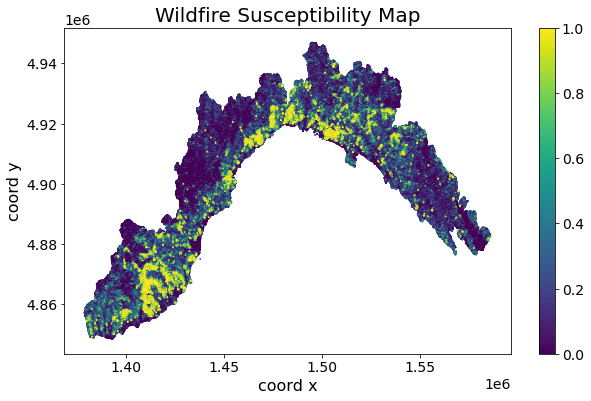